In [3]:
import numpy as np
import pandas as pd
from pathlib import Path
from matplotlib import pyplot as plt
import seaborn as sns

from ex_01_read_data import get_welding_data
from ex_03_feature_extraction import extract_features

In [4]:
data_path = Path("data/Welding/data.csv")
plot_path = Path("plots/ex_03")
plot_path.mkdir(parents=True, exist_ok=True)

## Exercise 3.3: Feature Exploration with Pairplots

In this exercise, you will create a seaborn pairplot to visualize relationships between the features extracted from the welding data. 

In [5]:
n_samples = 1_000
data, labels, _ = get_welding_data(data_path, n_samples=n_samples)
features = extract_features(data, labels)
features.head()

,voltage_mean,voltage_std,voltage_median,voltage_min,voltage_max,voltage_rms,voltage_dominant_frequency,voltage_spectral_power,current_mean,current_std,...,current_min,current_max,current_rms,current_dominant_frequency,current_spectral_power,mean_power,power_std,apparent_power,mean_absolute_power,quality
0,160.758205,181.552064,44.224704,36.317329,533.766162,242.496087,500.0,1.692951e+09,22.020253,3.878667,...,18.230588,29.954216,22.359239,500.0,1.969654e+07,4234.792754,5425.100302,5422.028072,4234.792754,0
1,313.638104,215.878585,430.298650,28.870729,602.292886,380.752444,500.0,4.866828e+09,11.331396,5.227773,...,2.446285,26.375136,12.479189,1000.0,5.682657e+06,3193.622931,3006.054352,4751.481686,3193.622931,0
2,165.821793,176.946911,68.492529,28.879433,532.293628,242.501704,500.0,1.726079e+09,24.291817,3.872061,...,20.166386,32.402682,24.598480,500.0,2.390355e+07,4710.111872,5695.728068,5965.173389,4710.111872,0
3,166.058743,175.900198,70.689933,28.634610,532.197580,241.901603,500.0,1.721838e+09,24.790640,3.856320,...,19.859189,32.625101,25.088783,500.0,2.488046e+07,4787.757653,5744.709721,6069.016774,4787.757653,0
4,237.498872,183.374518,125.259166,60.381105,528.436541,300.053209,500.0,2.928753e+09,24.224219,4.025947,...,20.189609,30.856069,24.556487,500.0,2.379669e+07,6486.174228,5861.971605,7368.252752,6486.174228,0


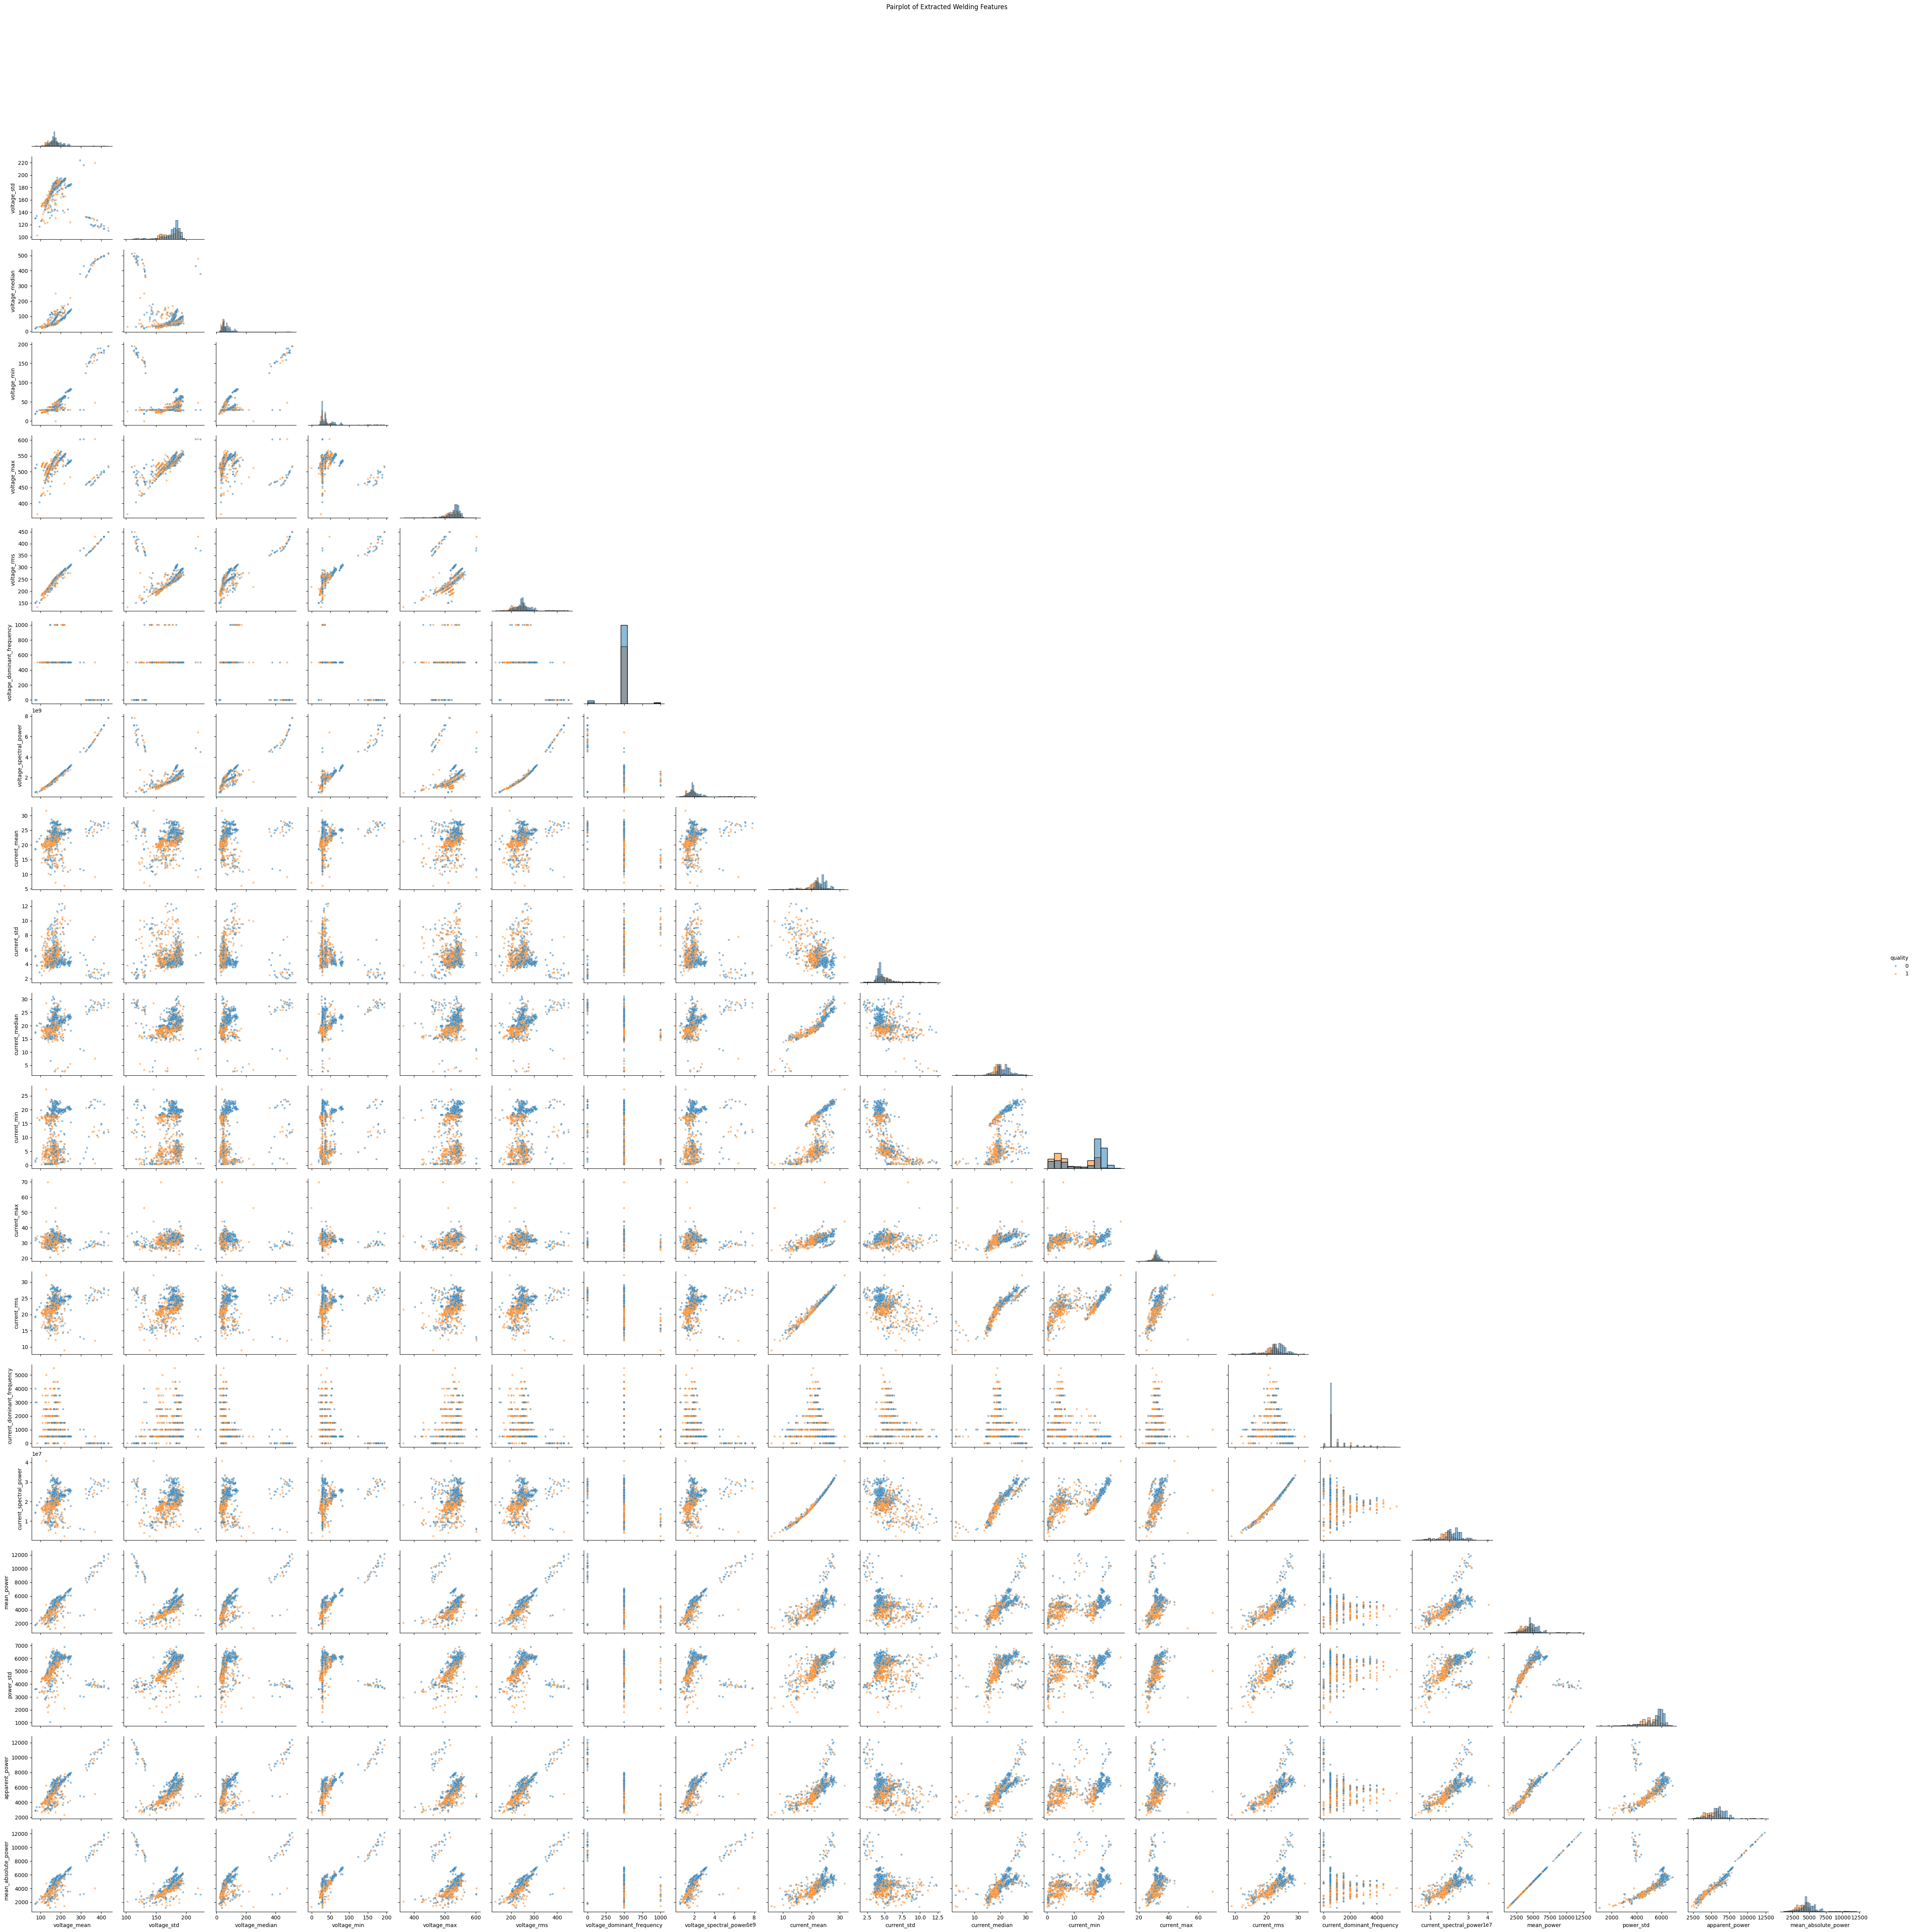

In [6]:

# Create pairplot

# Use quality labels to distinguish between classes
pairplot = sns.pairplot(
    features,
    hue="quality",
    diag_kind="hist",
    corner=True,
    plot_kws={"alpha": 0.5, "s": 15}
)

# Add a title
pairplot.fig.suptitle(
    "Pairplot of Extracted Welding Features",
    y=1.02
)

# Save visualization
pairplot.fig.savefig(
    plot_path / "feature_pairplot.png",
    dpi=300,
    bbox_inches="tight"
)

# Display visualization
plt.show()


## Exercise 3.4: Describe Your Feature Selection

Based on the pairplot visualization from Exercise 3.1, provide a detailed analysis of your feature selection:

1. Which features appear most effective at separating the quality classes?
2. Are there features that show strong correlation with each other? Would it make sense to remove any redundant features?
3. Explain the physical significance of your selected features in the context of welding quality.
4. If you were to select a subset of 5 most important features for classifying welding quality, which would you choose and why?
5. Discuss any patterns or insights you discovered in the data visualization that might help with building a classification model.


1. Overall, no single feature appears to separate classes perfectly. However, there some features that show some separation, but with big overlap:
  1. Current Std
  2. Current Max
  3. Current rms
  4. Current kurtosis
  5. Voltage mean
  6. Voltage energy

2. Yes, there are some features that have strong correlation:
  1. mean and rms
  2. mean and median
  3. min and range
  4. max and range
  5. rms and energy
  6. mean and energy

  It would make sense to remove some highly correlated features to reduce redundancy.

3. Extracted features describe physical properties of the welding process, such as current and voltage characteristics.
  1. mean -> average welding current or voltage
  2. std ->  measures fulctuations in current or voltage, can indicate process instability
  3. min -> lowest current or voltage
  4. max -> max current or voltage
  5. median -> shows central signal value, less sensitive to outliers than mean
  6. range -> measures overall variation of signal
  7. rms -> shows effective magnitude of the electrical signal
  8. skewness -> describes whether signal contains deviations in one direction
  9. kurtosis -> shows how strongly signal contains outliers
  10. energy -> shows the accumulated squared signal magnitude

4. The 5 most important features:
  1. current mean -> captures average welding current that represents differences in operating conditions
  2. current std -> captures current fluctuations, and provides info about process stability
  3. current skewness -> captures assymetry in signal distribution
  4. voltage mean -> average welding voltage, useful for welding process analysis
  5. voltage std -> captures voltage fluctuations, gives info about welding process stability

5. Insights:
  1. Several current features have high correlation. Removing them can reduce redundancy.
  2. Some features show highly overlap between two welding quality classes, what suggests that individual features are not enough for reliable classification,
  3. Some feature combinations produce high amount of outliers, what suggests unusual welding conditions or measurement anomylies. This must be investigated before deciding to remove them.